# Phase 1: Exploratory Data Analysis

This notebook performs comprehensive EDA on the rocket failures dataset with 15+ visualizations.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import sys
from pathlib import Path
import os
import importlib.util
from collections import Counter
from nltk import FreqDist
import nltk

# Load config module directly from file
config_path = Path(os.path.abspath('')).parent / 'config.py'
spec = importlib.util.spec_from_file_location("config", config_path)
config = importlib.util.module_from_spec(spec)
spec.loader.exec_module(config)

CSV_PATH = config.CSV_PATH
FIGURES_DIR = config.FIGURES_DIR

# Download NLTK resources
nltk.download('punkt')
nltk.download('stopwords')

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Load data
df = pd.read_csv(CSV_PATH)
df['date'] = pd.to_datetime(df['date'])
print(f"Loaded {len(df)} records")

[nltk_data] Downloading package punkt to
[nltk_data]     .../nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     .../nltk_data...


Loaded 500 records


[nltk_data]   Unzipping corpora\stopwords.zip.


## 1. Temporal Analysis

### 1.1 Incidents per Year (Line Plot)

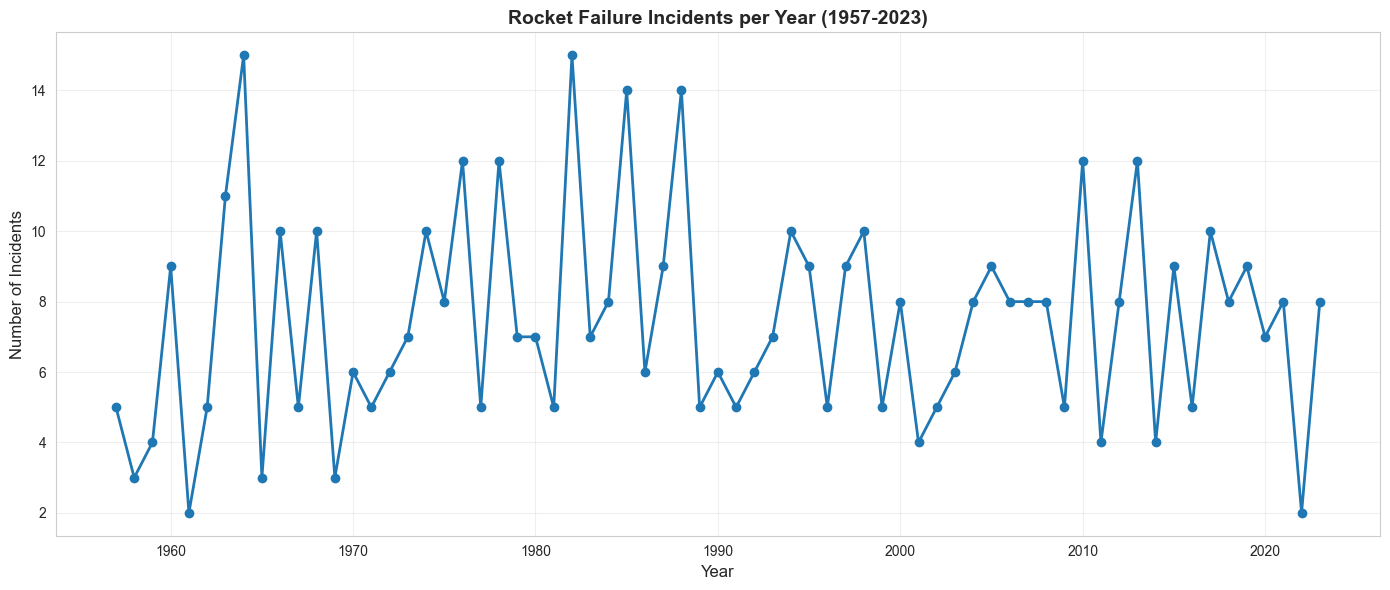

In [5]:
yearly_counts = df.groupby('year').size()

plt.figure(figsize=(14, 6))
yearly_counts.plot(kind='line', marker='o', linewidth=2)
plt.title('Rocket Failure Incidents per Year (1957-2023)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Incidents', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_incidents_per_year.png', dpi=300, bbox_inches='tight')
plt.show()

### 1.2 Incidents per Decade (Bar Chart)

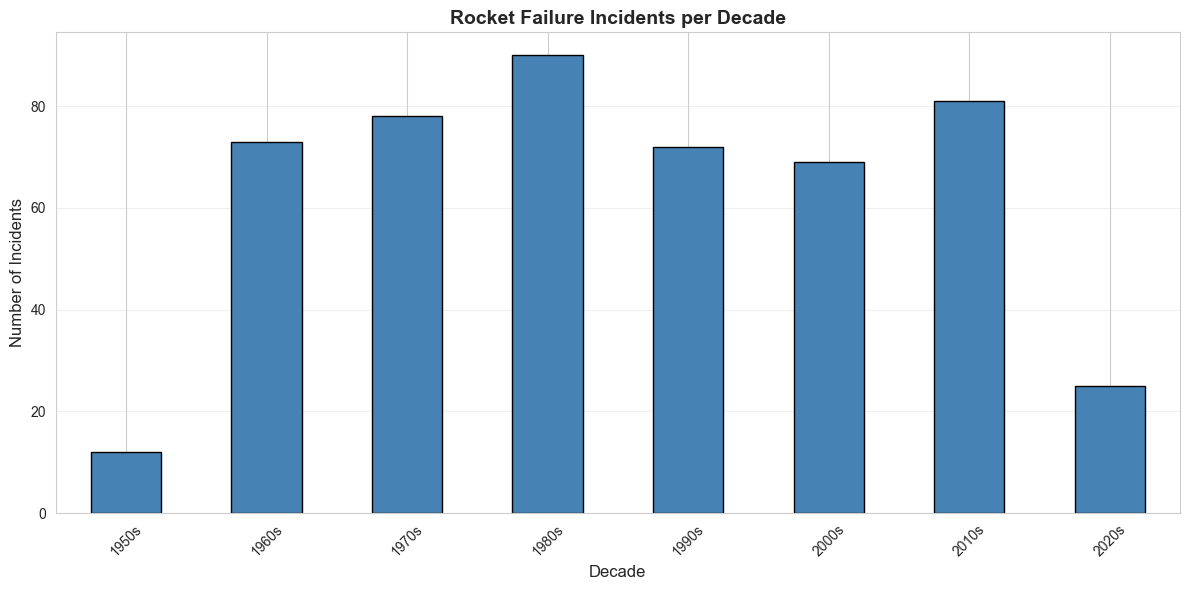

In [6]:
decade_counts = df['decade'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
decade_counts.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Rocket Failure Incidents per Decade', fontsize=14, fontweight='bold')
plt.xlabel('Decade', fontsize=12)
plt.ylabel('Number of Incidents', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_incidents_per_decade.png', dpi=300, bbox_inches='tight')
plt.show()

### 1.3 Monthly Distribution of Failures (Heatmap)

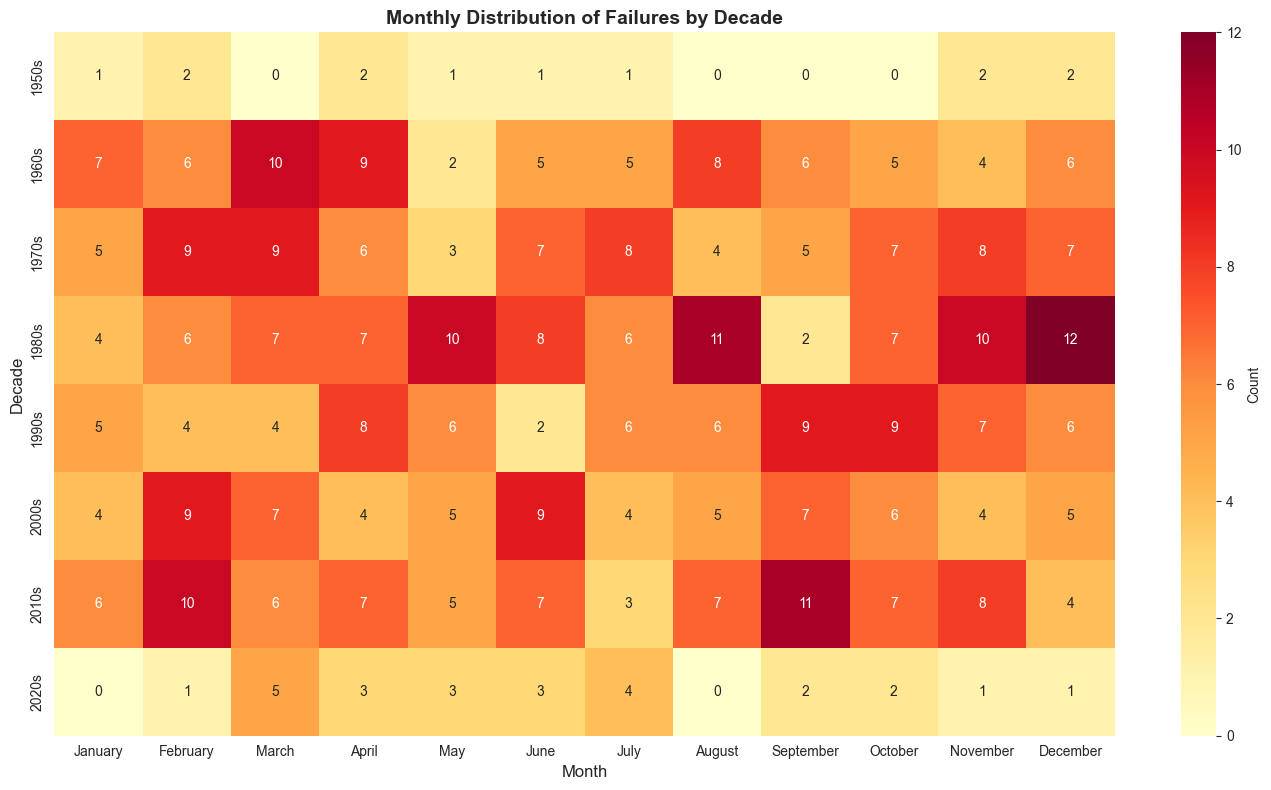

In [7]:
# Create month-year pivot
df['month'] = df['date'].dt.month_name()
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

month_decade = df.groupby(['decade', 'month']).size().unstack(fill_value=0)
month_decade = month_decade[month_order]

plt.figure(figsize=(14, 8))
sns.heatmap(month_decade, annot=True, fmt='d', cmap='YlOrRd', cbar_kws={'label': 'Count'})
plt.title('Monthly Distribution of Failures by Decade', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Decade', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_monthly_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### 1.4 Trend of Failure Types over Decades

<Figure size 1400x800 with 0 Axes>

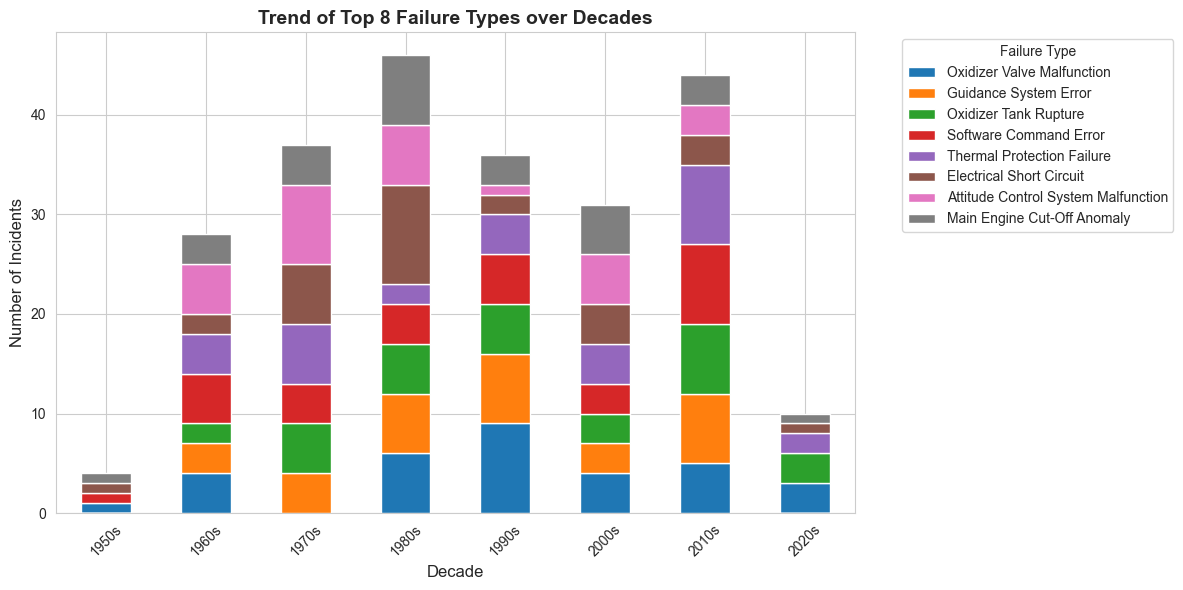

In [8]:
failure_decade = df.groupby(['decade', 'failure_type']).size().unstack(fill_value=0)
top_failures = failure_decade.sum().nlargest(8).index
failure_decade_top = failure_decade[top_failures]

plt.figure(figsize=(14, 8))
failure_decade_top.plot(kind='bar', stacked=True)
plt.title('Trend of Top 8 Failure Types over Decades', fontsize=14, fontweight='bold')
plt.xlabel('Decade', fontsize=12)
plt.ylabel('Number of Incidents', fontsize=12)
plt.legend(title='Failure Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_failure_type_trend.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Vehicle & Country Analysis

### 2.1 Top 10 Vehicles with Most Failures (Horizontal Bar)

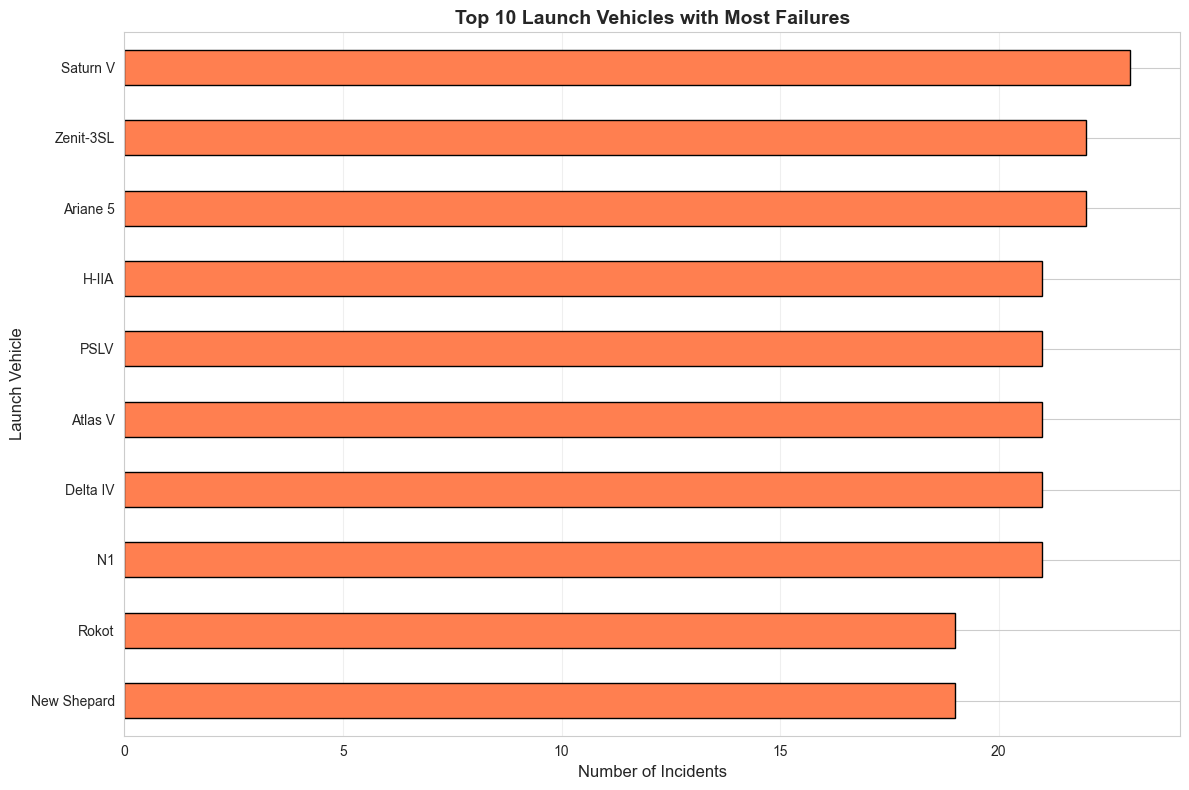

In [9]:
vehicle_counts = df['launch_vehicle'].value_counts().nlargest(10)

plt.figure(figsize=(12, 8))
vehicle_counts.sort_values().plot(kind='barh', color='coral', edgecolor='black')
plt.title('Top 10 Launch Vehicles with Most Failures', fontsize=14, fontweight='bold')
plt.xlabel('Number of Incidents', fontsize=12)
plt.ylabel('Launch Vehicle', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_top_10_vehicles.png', dpi=300, bbox_inches='tight')
plt.show()

### 2.2 Country-wise Failure Distribution (Pie Chart)

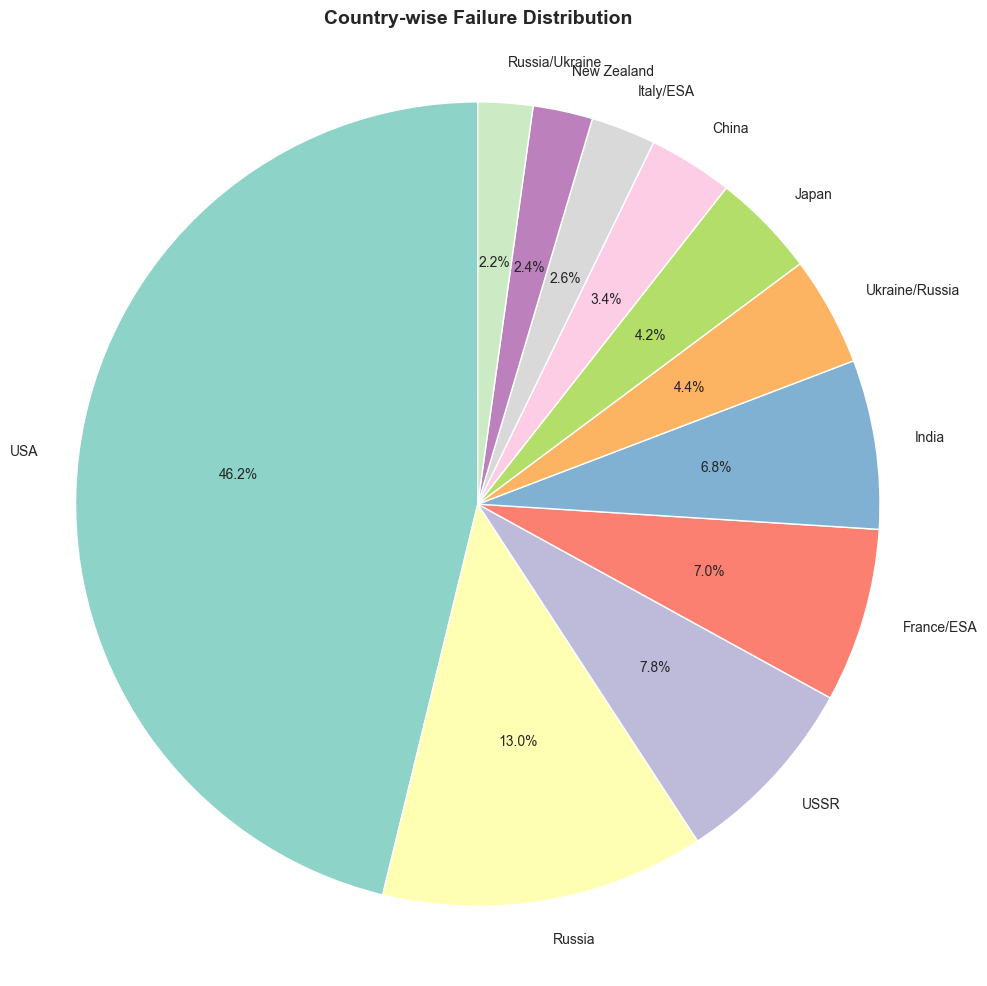

In [10]:
country_counts = df['country'].value_counts()

plt.figure(figsize=(10, 10))
plt.pie(country_counts.values, labels=country_counts.index, autopct='%1.1f%%', 
        startangle=90, colors=plt.cm.Set3(range(len(country_counts))))
plt.title('Country-wise Failure Distribution', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '06_country_pie.png', dpi=300, bbox_inches='tight')
plt.show()

### 2.3 Country-wise Failure Distribution (Bar Chart)

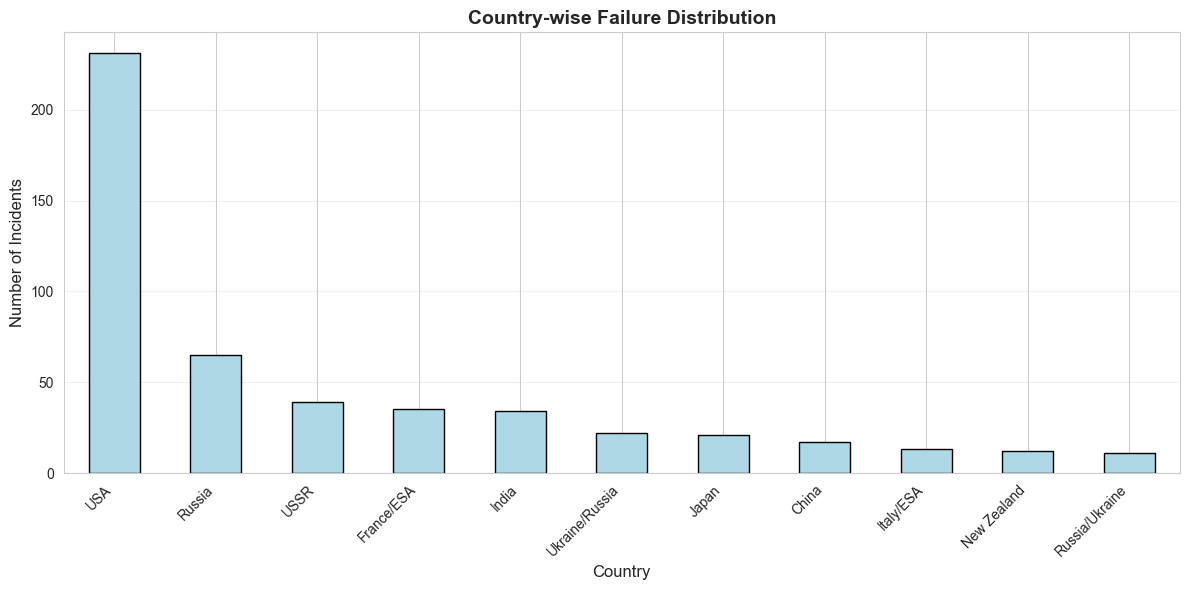

In [11]:
plt.figure(figsize=(12, 6))
country_counts.plot(kind='bar', color='lightblue', edgecolor='black')
plt.title('Country-wise Failure Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Country', fontsize=12)
plt.ylabel('Number of Incidents', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '07_country_bar.png', dpi=300, bbox_inches='tight')
plt.show()

### 2.4 Launch Site Frequency

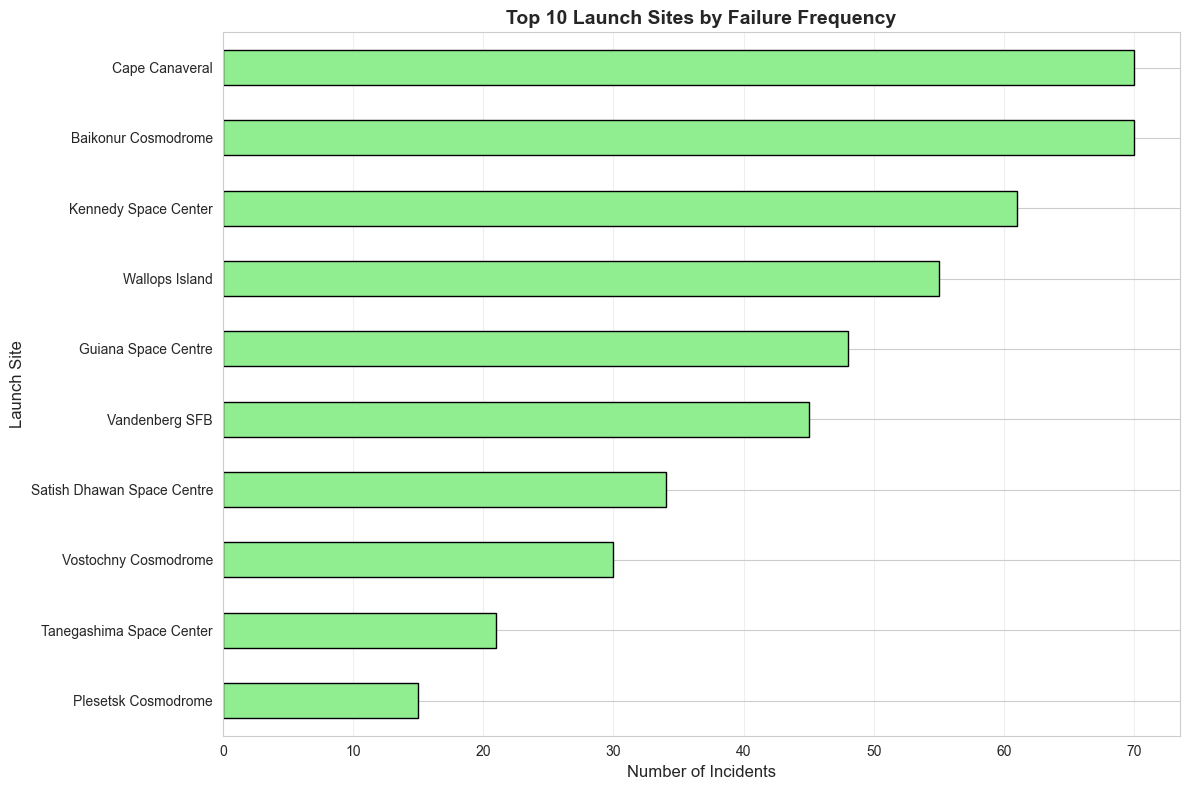

In [12]:
site_counts = df['launch_site'].value_counts().nlargest(10)

plt.figure(figsize=(12, 8))
site_counts.sort_values().plot(kind='barh', color='lightgreen', edgecolor='black')
plt.title('Top 10 Launch Sites by Failure Frequency', fontsize=14, fontweight='bold')
plt.xlabel('Number of Incidents', fontsize=12)
plt.ylabel('Launch Site', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '08_launch_sites.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Failure Characterization

### 3.1 Failure Type Distribution (Bar Chart)

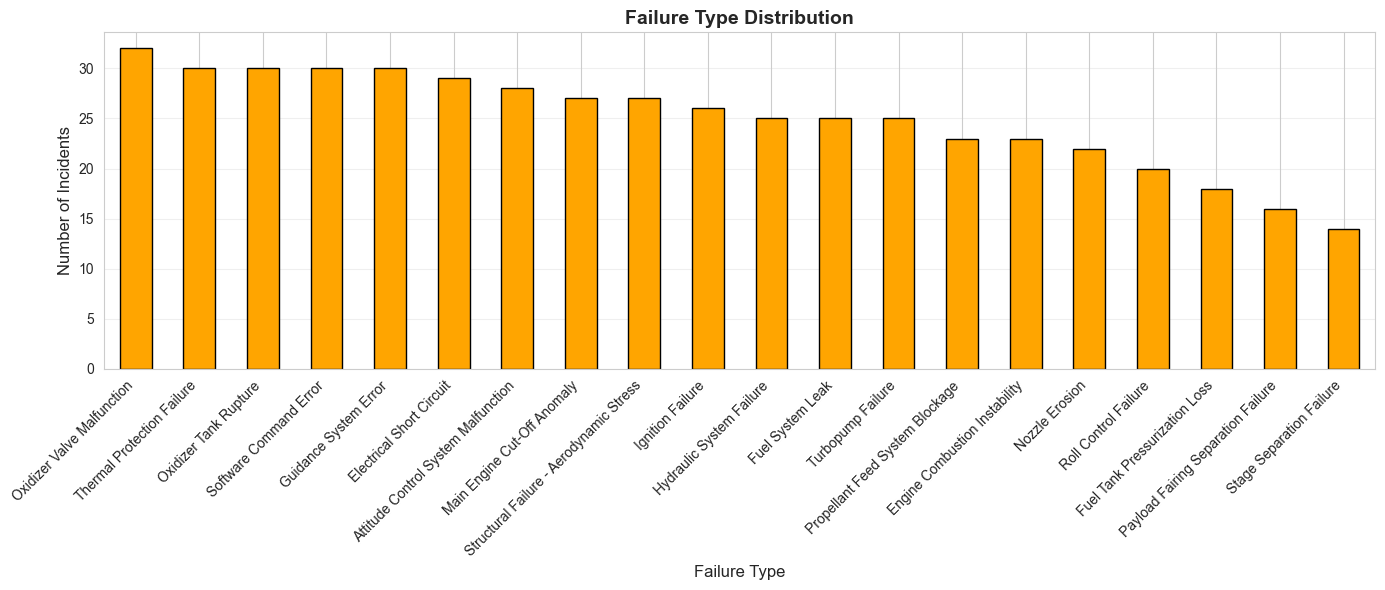

In [13]:
failure_type_counts = df['failure_type'].value_counts()

plt.figure(figsize=(14, 6))
failure_type_counts.plot(kind='bar', color='orange', edgecolor='black')
plt.title('Failure Type Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Failure Type', fontsize=12)
plt.ylabel('Number of Incidents', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '09_failure_type_bar.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.2 Failure Category vs Failure Phase (Heatmap)

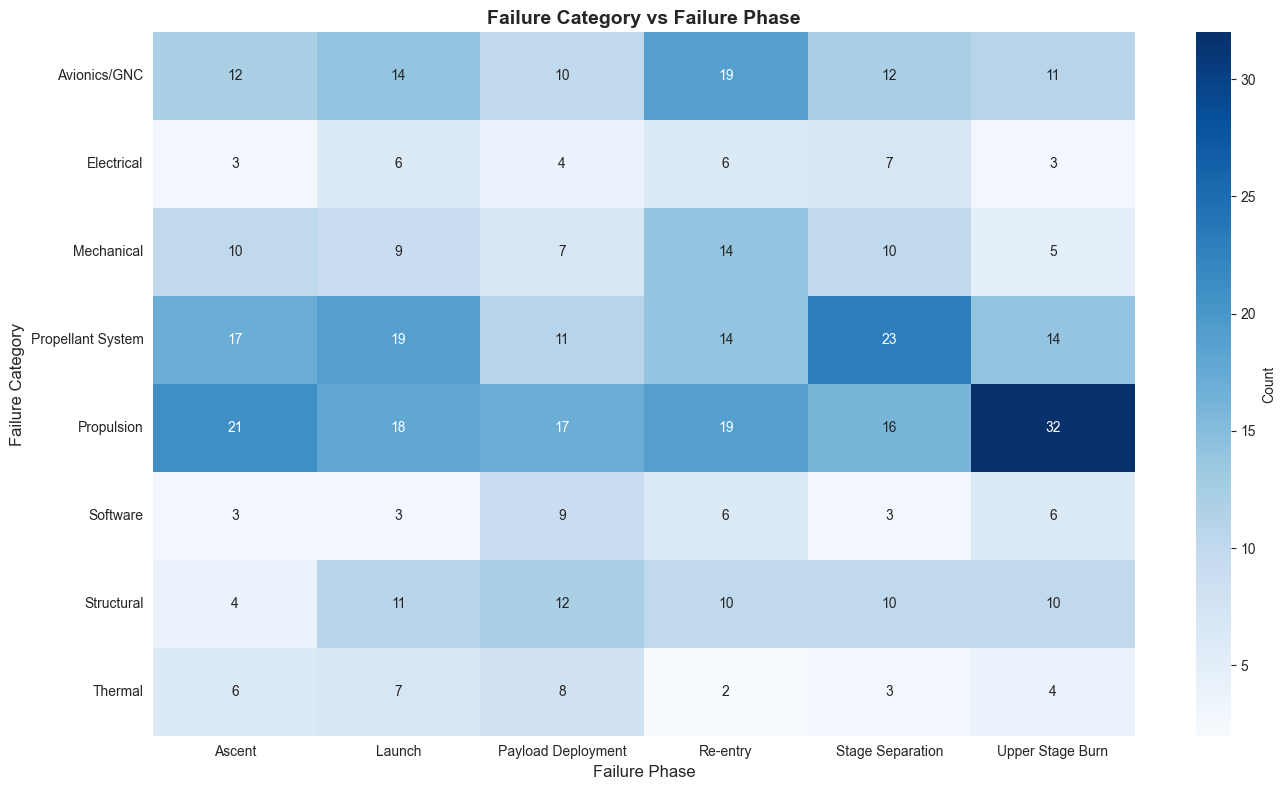

In [14]:
category_phase = df.groupby(['failure_category', 'failure_phase']).size().unstack(fill_value=0)

plt.figure(figsize=(14, 8))
sns.heatmap(category_phase, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Count'})
plt.title('Failure Category vs Failure Phase', fontsize=14, fontweight='bold')
plt.xlabel('Failure Phase', fontsize=12)
plt.ylabel('Failure Category', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '10_category_phase_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.3 Severity Level Distribution

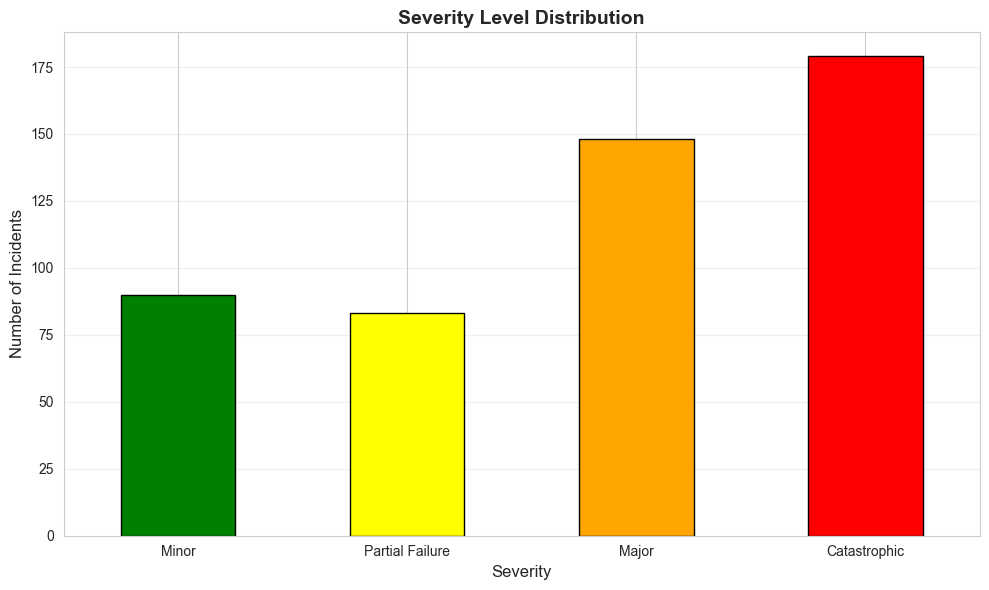

In [15]:
severity_counts = df['severity'].value_counts()
severity_order = ['Minor', 'Partial Failure', 'Major', 'Catastrophic']
severity_counts = severity_counts.reindex(severity_order, fill_value=0)

plt.figure(figsize=(10, 6))
severity_counts.plot(kind='bar', color=['green', 'yellow', 'orange', 'red'], edgecolor='black')
plt.title('Severity Level Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Severity', fontsize=12)
plt.ylabel('Number of Incidents', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '11_severity_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.4 Propellant Type vs Failure Frequency

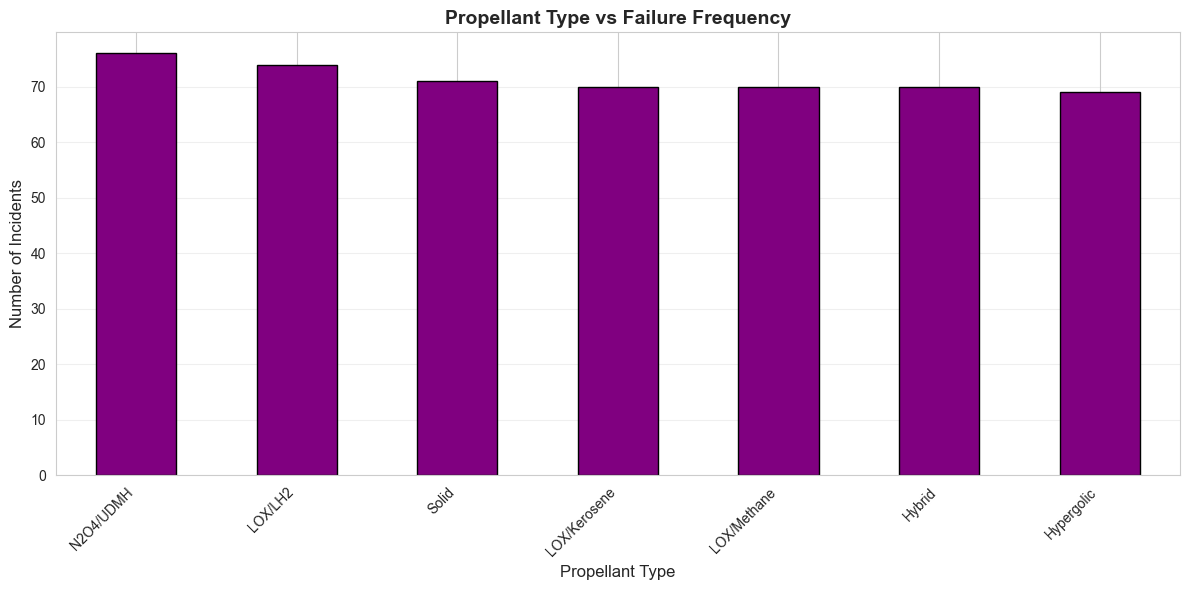

In [16]:
propellant_counts = df['propellant_type'].value_counts()

plt.figure(figsize=(12, 6))
propellant_counts.plot(kind='bar', color='purple', edgecolor='black')
plt.title('Propellant Type vs Failure Frequency', fontsize=14, fontweight='bold')
plt.xlabel('Propellant Type', fontsize=12)
plt.ylabel('Number of Incidents', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '12_propellant_frequency.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Numerical Feature Analysis

### 4.1 Histogram + KDE for altitude_km

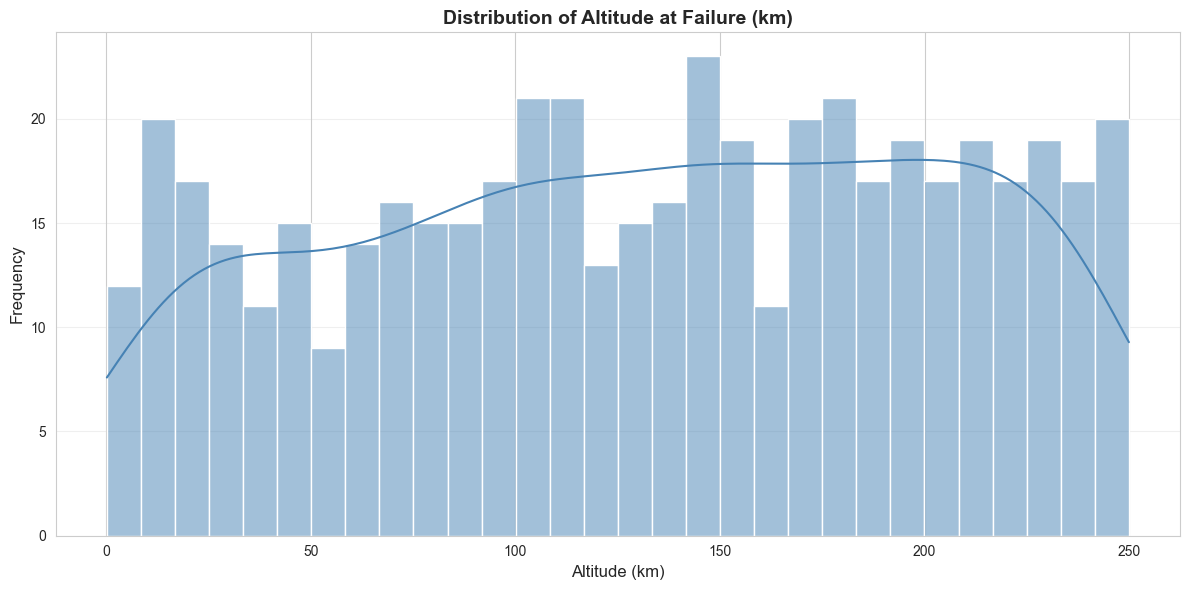

In [17]:
plt.figure(figsize=(12, 6))
sns.histplot(df['altitude_km'], kde=True, bins=30, color='steelblue')
plt.title('Distribution of Altitude at Failure (km)', fontsize=14, fontweight='bold')
plt.xlabel('Altitude (km)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '13_altitude_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

### 4.2 Histogram + KDE for time_to_failure_sec

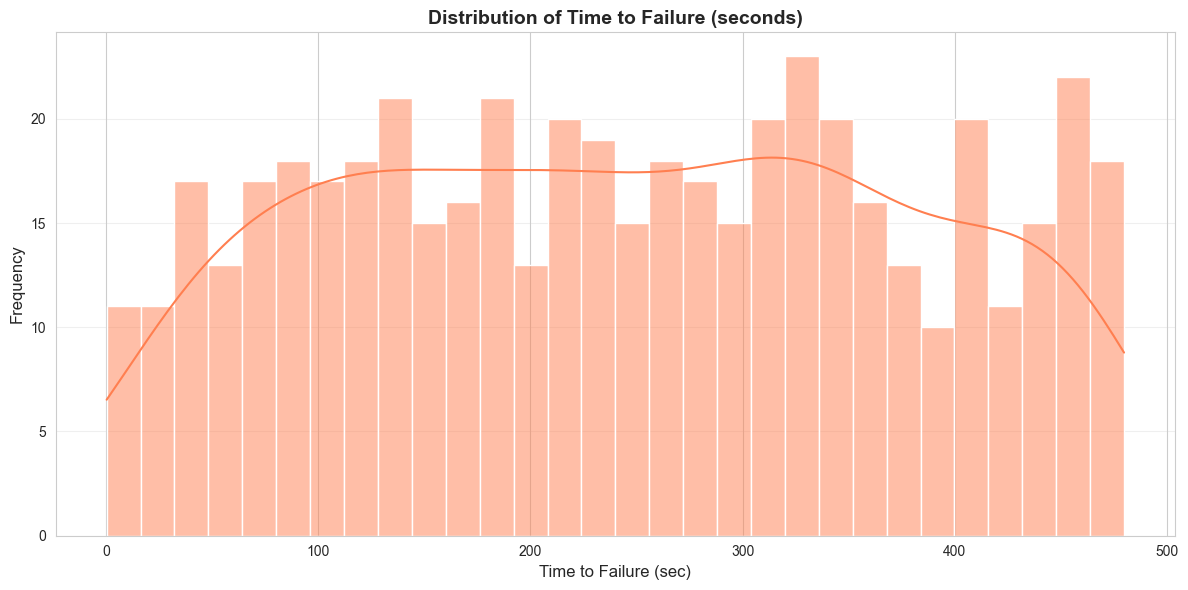

In [18]:
plt.figure(figsize=(12, 6))
sns.histplot(df['time_to_failure_sec'], kde=True, bins=30, color='coral')
plt.title('Distribution of Time to Failure (seconds)', fontsize=14, fontweight='bold')
plt.xlabel('Time to Failure (sec)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '14_time_to_failure_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

### 4.3 Boxplot of Altitude by Severity

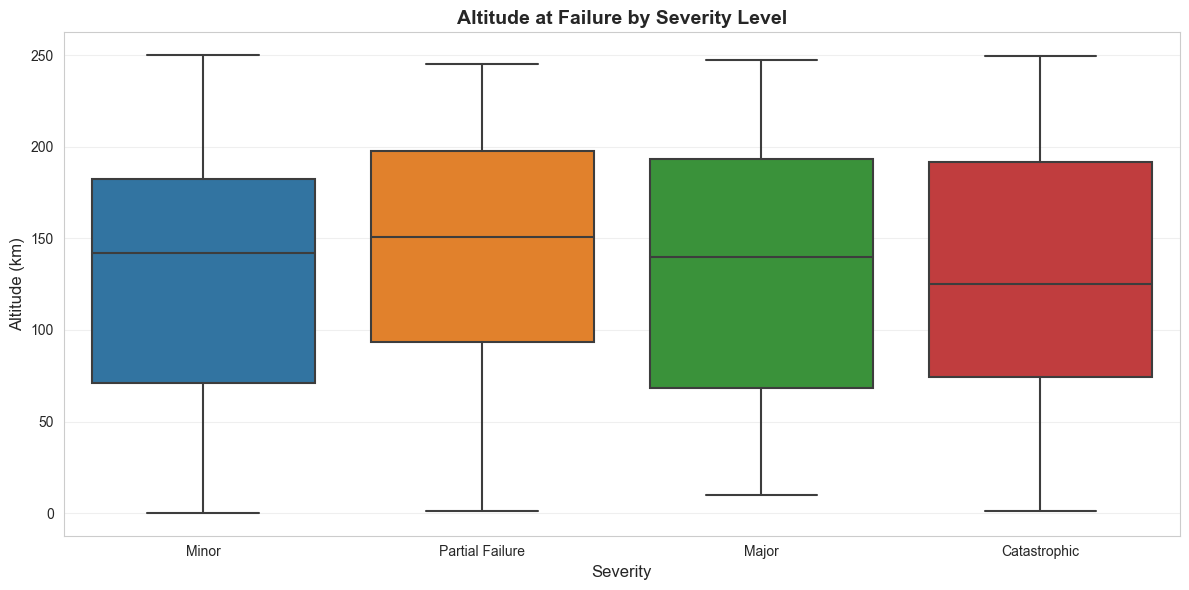

In [19]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='severity', y='altitude_km', data=df, order=severity_order)
plt.title('Altitude at Failure by Severity Level', fontsize=14, fontweight='bold')
plt.xlabel('Severity', fontsize=12)
plt.ylabel('Altitude (km)', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '15_altitude_by_severity_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

### 4.4 Correlation Heatmap for Numeric Features

In [20]:
numeric_cols = ['year', 'month', 'altitude_km', 'time_to_failure_sec', 'mission_success']
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={'label': 'Correlation'})
plt.title('Correlation Heatmap for Numeric Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '16_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

ValueError: could not convert string to float: 'January'

### 4.5 Scatter: altitude_km vs time_to_failure_sec (color by severity)

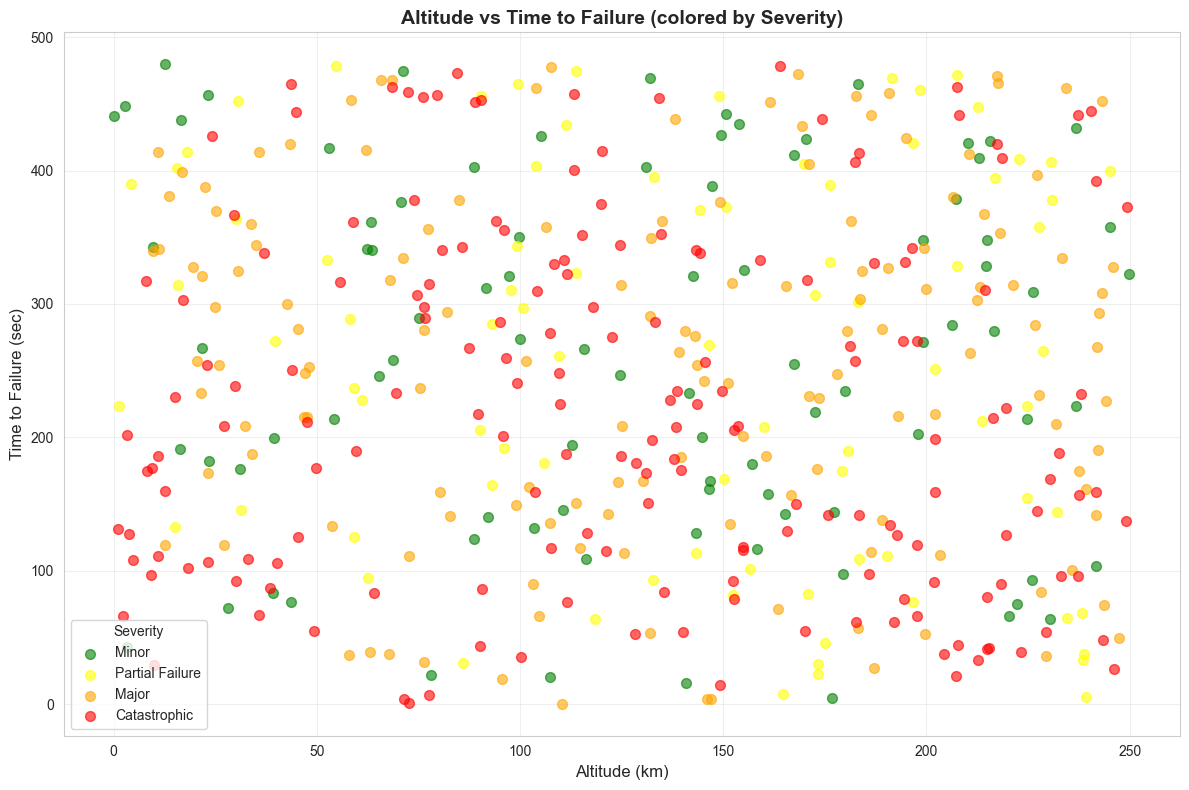

In [21]:
plt.figure(figsize=(12, 8))
severity_colors = {'Minor': 'green', 'Partial Failure': 'yellow', 
                   'Major': 'orange', 'Catastrophic': 'red'}
for severity in severity_order:
    subset = df[df['severity'] == severity]
    plt.scatter(subset['altitude_km'], subset['time_to_failure_sec'], 
               label=severity, color=severity_colors[severity], alpha=0.6, s=50)

plt.title('Altitude vs Time to Failure (colored by Severity)', fontsize=14, fontweight='bold')
plt.xlabel('Altitude (km)', fontsize=12)
plt.ylabel('Time to Failure (sec)', fontsize=12)
plt.legend(title='Severity')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '17_altitude_time_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Text Feature Analysis

### 5.1 Word Frequency Analysis - Top 30 Unigrams

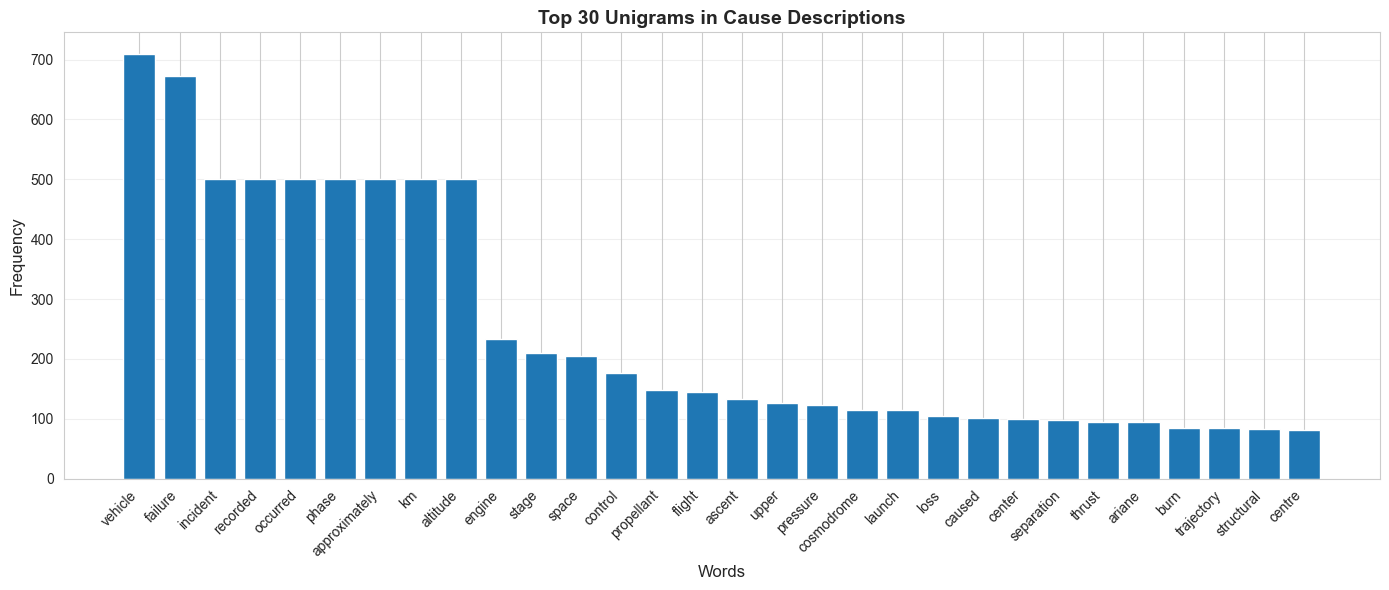

In [22]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import re

# Combine cause_description and notes
all_text = ' '.join(df['cause_description'].fillna('') + ' ' + df['notes'].fillna(''))

# Tokenize and clean
tokens = word_tokenize(all_text.lower())
tokens = [t for t in tokens if t.isalpha() and t not in stopwords.words('english')]

# Get top 30 unigrams
fdist = FreqDist(tokens)
top_30 = fdist.most_common(30)

plt.figure(figsize=(14, 6))
words, counts = zip(*top_30)
plt.bar(range(len(words)), counts)
plt.xticks(range(len(words)), words, rotation=45, ha='right')
plt.title('Top 30 Unigrams in Cause Descriptions', fontsize=14, fontweight='bold')
plt.xlabel('Words', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '18_top_30_unigrams.png', dpi=300, bbox_inches='tight')
plt.show()

### 5.2 Top 30 Bigrams

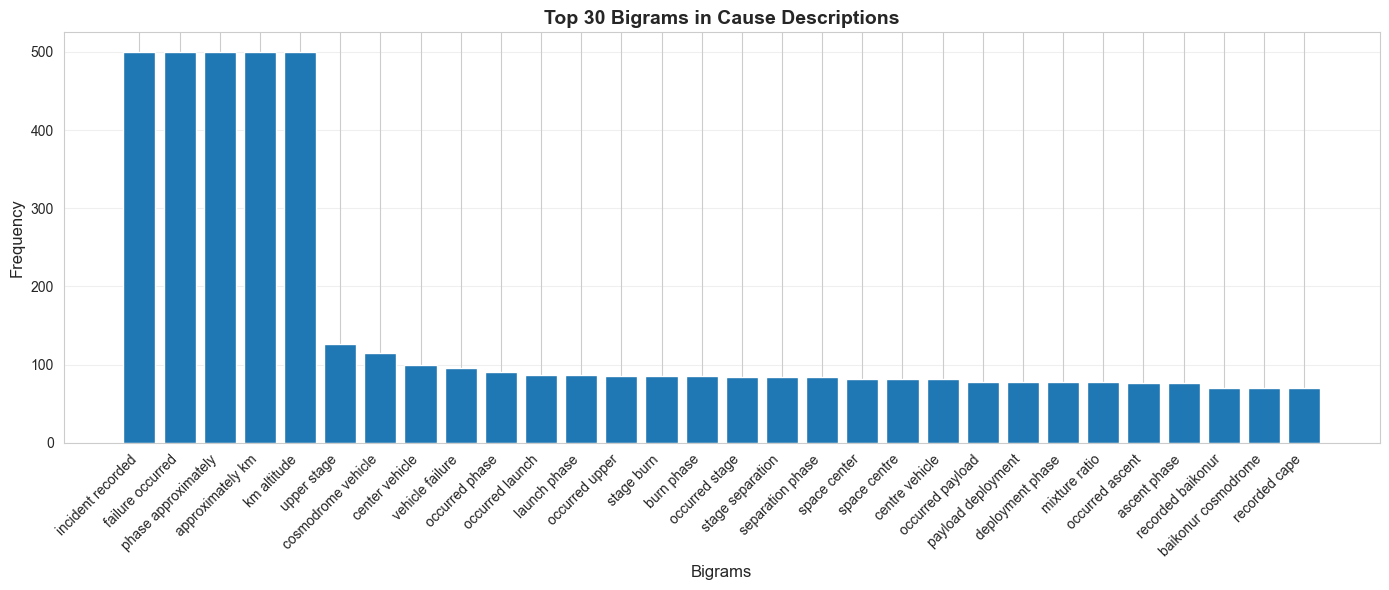

In [23]:
from nltk import bigrams

# Get bigrams
bigram_list = list(bigrams(tokens))
fdist_bigrams = FreqDist(bigram_list)
top_30_bigrams = fdist_bigrams.most_common(30)

plt.figure(figsize=(14, 6))
bigram_words = [' '.join(b) for b, c in top_30_bigrams]
bigram_counts = [c for b, c in top_30_bigrams]
plt.bar(range(len(bigram_words)), bigram_counts)
plt.xticks(range(len(bigram_words)), bigram_words, rotation=45, ha='right')
plt.title('Top 30 Bigrams in Cause Descriptions', fontsize=14, fontweight='bold')
plt.xlabel('Bigrams', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '19_top_30_bigrams.png', dpi=300, bbox_inches='tight')
plt.show()

### 5.3 WordCloud for cause_description grouped by failure_category

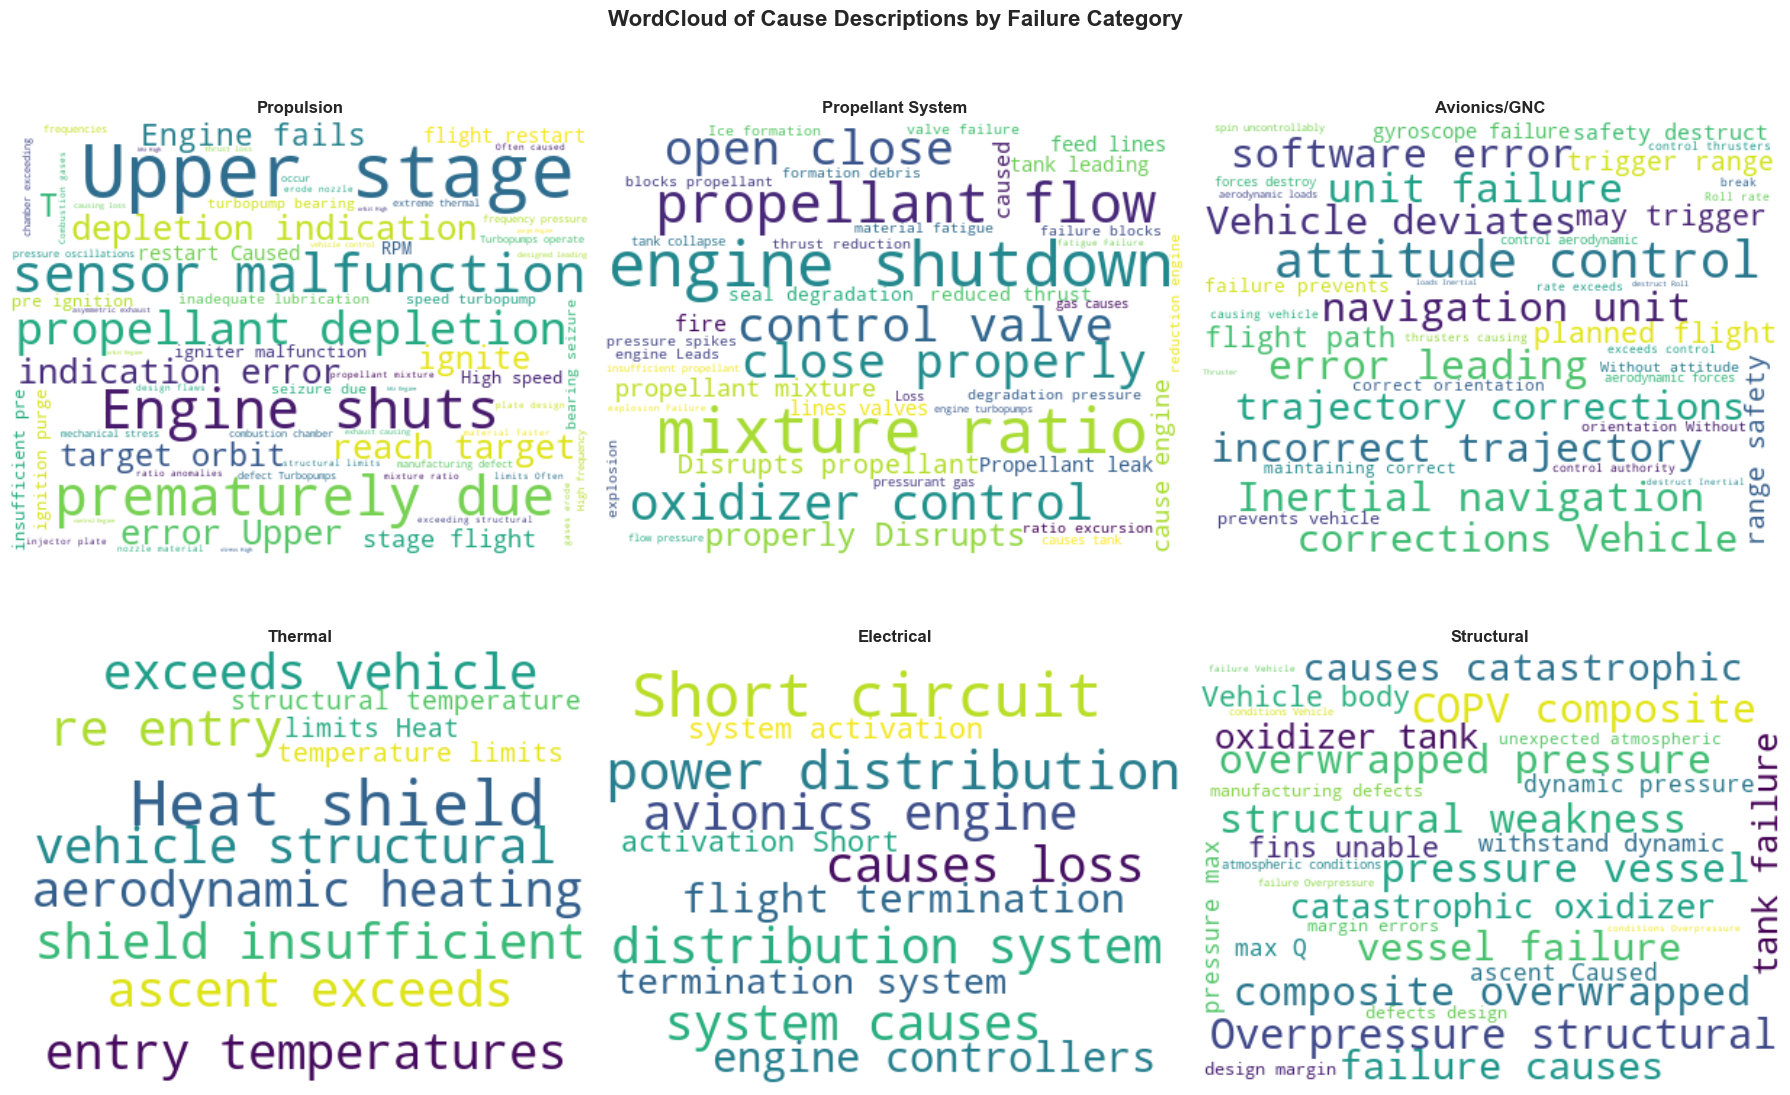

In [24]:
categories = df['failure_category'].unique()
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, category in enumerate(categories[:6]):
    category_text = ' '.join(df[df['failure_category'] == category]['cause_description'].fillna(''))
    wordcloud = WordCloud(width=400, height=300, background_color='white').generate(category_text)
    axes[idx].imshow(wordcloud, interpolation='bilinear')
    axes[idx].set_title(f'{category}', fontsize=12, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle('WordCloud of Cause Descriptions by Failure Category', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '20_wordcloud_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

### 5.4 Average Description Length per Severity Level

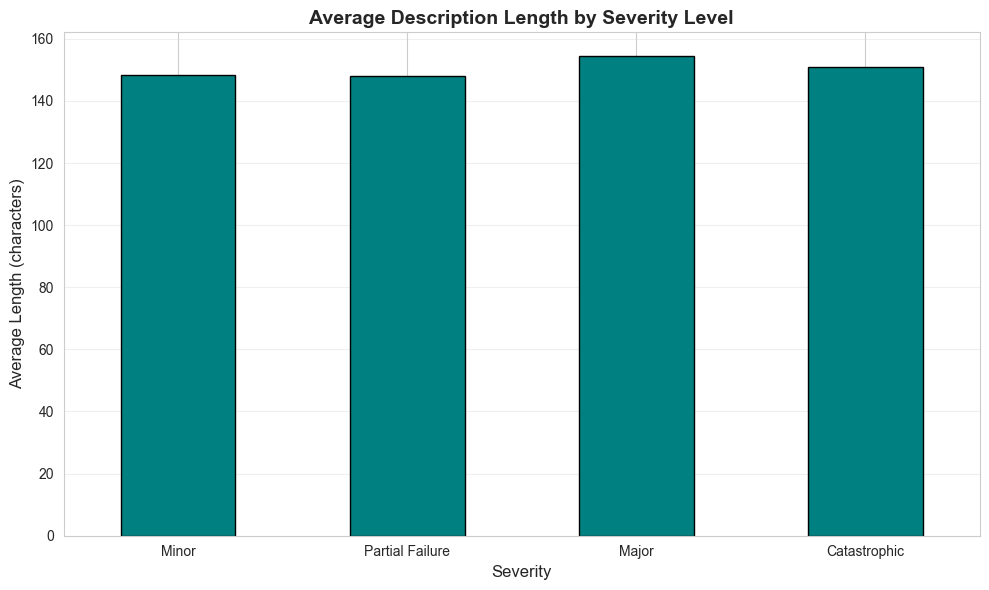

In [25]:
df['description_length'] = df['cause_description'].fillna('').str.len()
avg_length_by_severity = df.groupby('severity')['description_length'].mean()
avg_length_by_severity = avg_length_by_severity.reindex(severity_order)

plt.figure(figsize=(10, 6))
avg_length_by_severity.plot(kind='bar', color='teal', edgecolor='black')
plt.title('Average Description Length by Severity Level', fontsize=14, fontweight='bold')
plt.xlabel('Severity', fontsize=12)
plt.ylabel('Average Length (characters)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '21_avg_length_by_severity.png', dpi=300, bbox_inches='tight')
plt.show()

### 5.5 Token Count Distribution Histogram

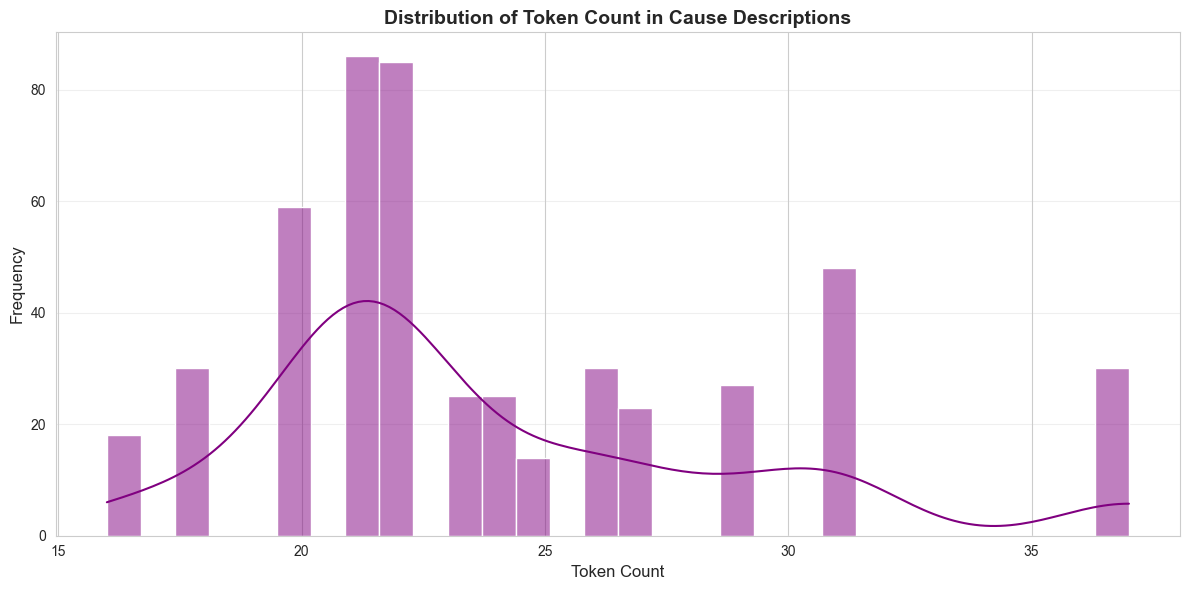

In [26]:
df['token_count'] = df['cause_description'].fillna('').apply(lambda x: len(word_tokenize(x)))

plt.figure(figsize=(12, 6))
sns.histplot(df['token_count'], kde=True, bins=30, color='purple')
plt.title('Distribution of Token Count in Cause Descriptions', fontsize=14, fontweight='bold')
plt.xlabel('Token Count', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '22_token_count_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Mission Success Analysis

### 6.1 Success vs Failure Rate Overall

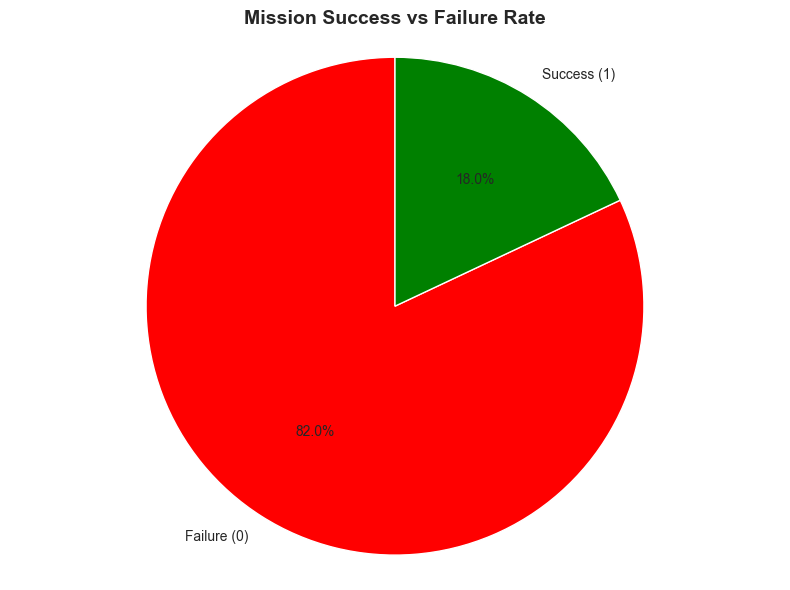

In [27]:
success_counts = df['mission_success'].value_counts()
success_labels = ['Failure (0)', 'Success (1)']

plt.figure(figsize=(8, 6))
plt.pie(success_counts.values, labels=success_labels, autopct='%1.1f%%', 
        startangle=90, colors=['red', 'green'])
plt.title('Mission Success vs Failure Rate', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '23_success_rate_pie.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.2 Success vs Failure Rate per Vehicle (Top 10)

<Figure size 1200x800 with 0 Axes>

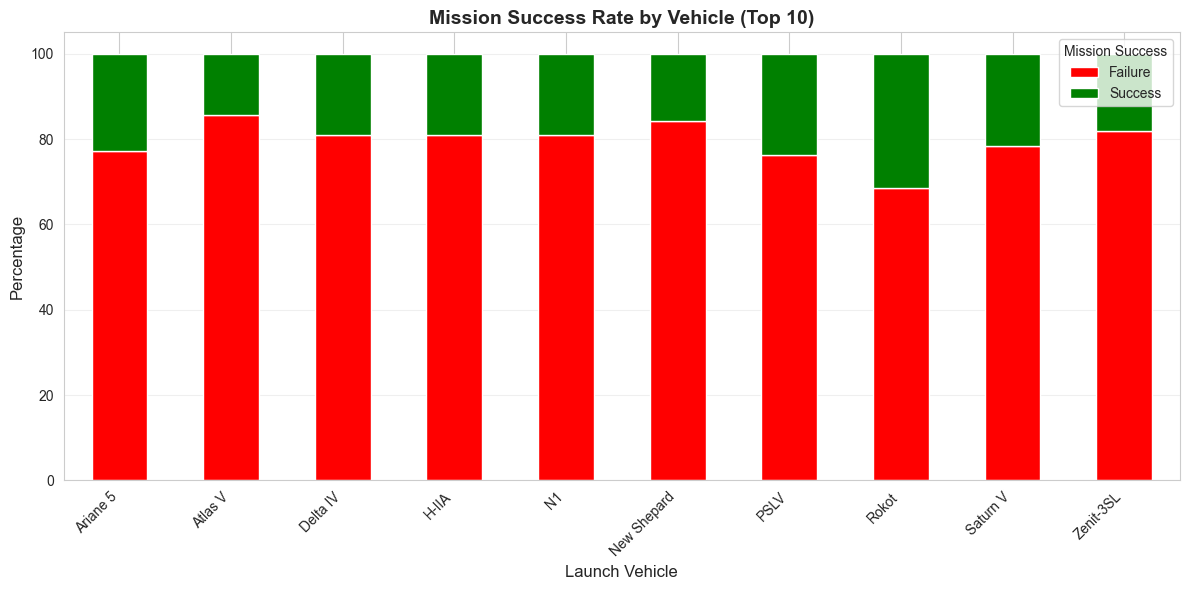

In [28]:
top_vehicles = df['launch_vehicle'].value_counts().nlargest(10).index
vehicle_success = df[df['launch_vehicle'].isin(top_vehicles)].groupby(['launch_vehicle', 'mission_success']).size().unstack(fill_value=0)

vehicle_success_pct = vehicle_success.div(vehicle_success.sum(axis=1), axis=0) * 100

plt.figure(figsize=(12, 8))
vehicle_success_pct.plot(kind='bar', stacked=True, color=['red', 'green'])
plt.title('Mission Success Rate by Vehicle (Top 10)', fontsize=14, fontweight='bold')
plt.xlabel('Launch Vehicle', fontsize=12)
plt.ylabel('Percentage', fontsize=12)
plt.legend(title='Mission Success', labels=['Failure', 'Success'])
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '24_success_rate_by_vehicle.png', dpi=300, bbox_inches='tight')
plt.show()

### 6.3 Chi-square Test: failure_type vs mission_success

In [29]:
from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(df['failure_type'], df['mission_success'])

# Perform chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-square Test: failure_type vs mission_success")
print(f"="*50)
print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Degrees of freedom: {dof}")
print(f"\nConclusion: {'Significant association' if p_value < 0.05 else 'No significant association'}")

Chi-square Test: failure_type vs mission_success
Chi-square statistic: 12.4723
P-value: 8.6446e-01
Degrees of freedom: 19

Conclusion: No significant association


### 6.4 Heatmap: decade vs failure_category (frequency)

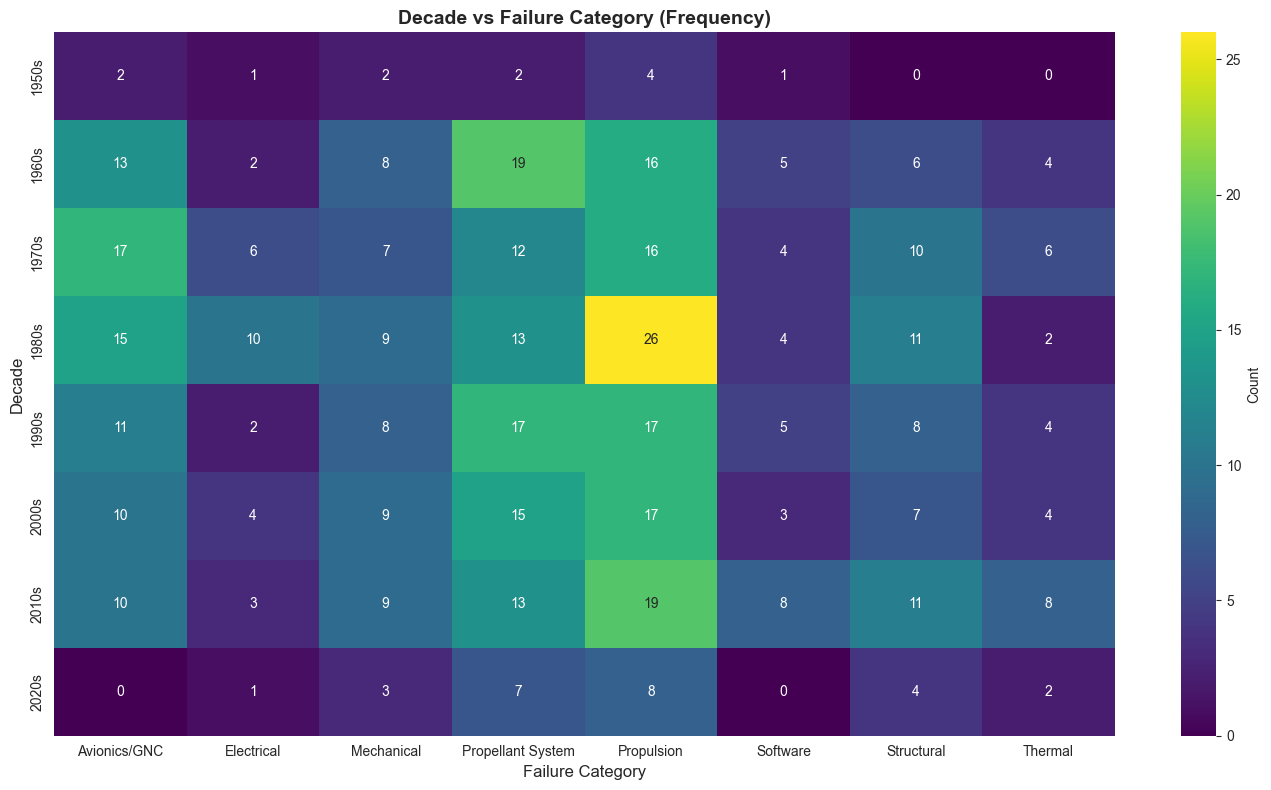

In [30]:
decade_category = df.groupby(['decade', 'failure_category']).size().unstack(fill_value=0)

plt.figure(figsize=(14, 8))
sns.heatmap(decade_category, annot=True, fmt='d', cmap='viridis', cbar_kws={'label': 'Count'})
plt.title('Decade vs Failure Category (Frequency)', fontsize=14, fontweight='bold')
plt.xlabel('Failure Category', fontsize=12)
plt.ylabel('Decade', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '25_decade_category_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## Summary

EDA complete! Generated 25 visualizations covering:
- Temporal analysis (4 plots)
- Vehicle & country analysis (4 plots)
- Failure characterization (4 plots)
- Numerical feature analysis (5 plots)
- Text feature analysis (5 plots)
- Mission success analysis (3 plots)

All plots saved to: `reports/figures/`